# 01 — Data Understanding & Cleaning
**Project:** Hotel Booking Analytics & Cancellation Prediction

**Objective:** inspect the source data, understand its quality, apply only defensible cleaning steps, and create a reusable cleaned dataset.

This notebook keeps the original booking records. Missing dates are not automatically imputed because their absence is strongly associated with booking status.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 40)
DATA_PATH = Path("../data/Hotels_Booking_Data.csv")
df = pd.read_csv(DATA_PATH)
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(" ", "_", regex=False)
              .str.replace("?", "", regex=False))

date_columns = ["booking_date", "check_in_date", "check_out_date", "travel_date"]
for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

df["coupon_used"] = (df["coupon_used"].astype(str).str.strip().str.lower()
                     .map({"yes": "Yes", "no": "No"}).fillna("Unknown"))
df["booking_status"] = df["booking_status"].astype(str).str.strip().str.title()
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [2]:
print("Shape:", df.shape)
display(df.head())
display(df.sample(5, random_state=42))

Shape: (30000, 26)


,customer_id,property_id,city,star_rating,booking_date,check_in_date,check_out_date,room_type,num_rooms_booked,stay_type,booking_channel,booking_value,costprice,markup,selling_price,payment_method,refund_status,refund_amount,channel_of_booking,booking_status,travel_date,cashback,coupon_redeem,coupon_used,length_of_stay,is_weekend_checkin
0,492,3,San Francisco,4,2024-04-01,2024-05-24,2024-05-26,Standard,1,Leisure,Mobile App,19361.0,19361,5981.0,25342.0,PayPal,Yes,369.65,Web,Confirmed,2024-03-04,5.37,0.0,No,2.0,True
1,180,3,Dallas,3,2024-04-01,2024-05-10,2024-05-17,Deluxe,1,Leisure,Mobile App,6137.0,6137,1896.0,8033.0,Bank Transfer,Yes,492.51,Web,Confirmed,2024-07-19,7.16,0.0,No,7.0,True
2,50,5,Dallas,3,2024-04-01,2024-05-31,2024-06-05,Deluxe,1,Business,Web,22702.0,22702,7013.0,29715.0,Debit Card,Yes,0.00,iOS,Confirmed,2024-03-22,0.00,0.0,No,5.0,True
3,294,3,Orlando,4,2024-04-01,2024-04-18,2024-04-24,Deluxe,3,Leisure,Web,34068.0,34068,10524.0,44592.0,Bank Transfer,Yes,545.54,Android,Confirmed,2024-11-24,7.93,24.5,Yes,6.0,False
4,40,5,Seattle,5,2024-04-01,NaT,NaT,Deluxe,1,Leisure,Mobile App,12127.0,12127,3746.0,15873.0,Debit Card,Yes,211.37,Web,Cancelled,2024-03-02,0.00,0.0,No,NaN,False


,customer_id,property_id,city,star_rating,booking_date,check_in_date,check_out_date,room_type,num_rooms_booked,stay_type,booking_channel,booking_value,costprice,markup,selling_price,payment_method,refund_status,refund_amount,channel_of_booking,booking_status,travel_date,cashback,coupon_redeem,coupon_used,length_of_stay,is_weekend_checkin
2308,469,1,Los Angeles,4,2024-05-01,2024-05-27,2024-06-01,Standard,1,Leisure,Web,21116.44,35377,10928.00,46305.00,Bank Transfer,Yes,577.40,Web,Confirmed,2024-07-31,8.40,0.00,No,5.0,False
22404,442,7,Las Vegas,2,2025-01-20,2025-02-18,2025-02-23,Deluxe,3,Leisure,Mobile App,17195.53,31574,9753.00,41327.00,PayPal,Yes,432.19,iOS,Confirmed,2024-10-14,0.00,-1.61,No,5.0,False
23397,15,1,Seattle,4,2025-02-02,2025-03-05,2025-03-12,Deluxe,3,Leisure,Mobile App,17966.00,17966,5550.00,23516.00,Credit Card,Yes,50.12,Web,Confirmed,2024-09-03,0.73,0.00,No,7.0,False
25058,330,5,San Francisco,3,2025-02-24,2025-04-01,2025-04-03,Suite,2,Leisure,Mobile App,19222.00,19222,5938.00,25160.00,Bank Transfer,Yes,690.18,Android,Confirmed,2024-08-06,0.00,0.00,No,2.0,False
2664,342,3,Orlando,4,2024-05-05,2024-06-02,2024-06-09,Standard,2,Leisure,Web,17446.64,16725,6458.75,23183.75,PayPal,Yes,0.00,Web,Confirmed,2024-11-26,4.31,19.05,Yes,7.0,True


## 1. Dataset structure
Each row is treated as one booking record. The dataset does not provide a separate booking identifier, so record counts are used as booking counts. `customer_id` and `property_id` are identifiers, not continuous measurements.

In [3]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id         30000 non-null  int64         
 1   property_id         30000 non-null  int64         
 2   city                30000 non-null  object        
 3   star_rating         30000 non-null  int64         
 4   booking_date        30000 non-null  datetime64[ns]
 5   check_in_date       24532 non-null  datetime64[ns]
 6   check_out_date      24532 non-null  datetime64[ns]
 7   room_type           30000 non-null  object        
 8   num_rooms_booked    30000 non-null  int64         
 9   stay_type           30000 non-null  object        
 10  booking_channel     30000 non-null  object        
 11  booking_value       30000 non-null  float64       
 12  costprice           30000 non-null  int64         
 13  markup              30000 non-null  float64   

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,30000.0,NaN,NaN,NaN,249.721767,1.0,123.0,248.0,376.0,499.0,145.484836
property_id,30000.0,NaN,NaN,NaN,3.777533,1.0,1.0,3.0,5.0,7.0,2.081471
city,30000,10,Chicago,3059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star_rating,30000.0,NaN,NaN,NaN,3.602033,2.0,3.0,4.0,4.0,5.0,0.860241
booking_date,30000,NaN,NaN,NaN,2024-10-14 12:00:02.880000,2024-04-01 00:00:00,2024-07-08 00:00:00,2024-10-14 12:00:00,2025-01-21 00:00:00,2025-04-30 00:00:00,NaN
check_in_date,24532,NaN,NaN,NaN,2024-11-14 03:36:32.401760768,2024-04-02 00:00:00,2024-08-08 00:00:00,2024-11-16 00:00:00,2025-02-20 00:00:00,2025-06-28 00:00:00,NaN
check_out_date,24532,NaN,NaN,NaN,2024-11-18 03:46:24.086091520,2024-04-04 00:00:00,2024-08-12 00:00:00,2024-11-19 12:00:00,2025-02-25 00:00:00,2025-07-03 00:00:00,NaN
room_type,30000,3,Standard,16552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_rooms_booked,30000.0,NaN,NaN,NaN,1.352333,1.0,1.0,1.0,2.0,3.0,0.574403
stay_type,30000,2,Leisure,18110,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality checks
Check duplicate rows, missing values, and category consistency before deciding how to handle them.

In [4]:
duplicate_count = df.duplicated().sum()
missing_summary = (df.isna().sum().to_frame("missing_count")
                   .assign(missing_percent=lambda x: x["missing_count"] / len(df) * 100)
                   .sort_values("missing_count", ascending=False))
print("Exact duplicate rows:", duplicate_count)
display(missing_summary)

Exact duplicate rows: 0


,missing_count,missing_percent
check_out_date,5468,18.226667
check_in_date,5468,18.226667
length_of_stay,5468,18.226667
property_id,0,0.000000
star_rating,0,0.000000
customer_id,0,0.000000
booking_date,0,0.000000
room_type,0,0.000000
num_rooms_booked,0,0.000000
city,0,0.000000


In [5]:
categorical_columns = df.select_dtypes(include="object").columns.tolist()
for column in categorical_columns:
    print(f"\\n{column}:")
    print(df[column].value_counts(dropna=False).head(15))

\ncity:
city
Chicago          3059
Los Angeles      3040
Las Vegas        3035
San Francisco    3032
Orlando          3015
New York         2993
Boston           2992
Miami            2959
Seattle          2940
Dallas           2935
Name: count, dtype: int64
\nroom_type:
room_type
Standard    16552
Deluxe      10478
Suite        2970
Name: count, dtype: int64
\nstay_type:
stay_type
Leisure     18110
Business    11890
Name: count, dtype: int64
\nbooking_channel:
booking_channel
Web             15001
Mobile App      12009
Travel Agent     2990
Name: count, dtype: int64
\npayment_method:
payment_method
Debit Card       7603
PayPal           7584
Credit Card      7492
Bank Transfer    7321
Name: count, dtype: int64
\nrefund_status:
refund_status
Yes    23182
No      6818
Name: count, dtype: int64
\nchannel_of_booking:
channel_of_booking
Web        16023
Android     9505
iOS         4472
Name: count, dtype: int64
\nbooking_status:
booking_status
Confirmed    21963
Cancelled     5779
Failed 

## 3. Missing dates by booking status
This is an important limitation. A large share of cancelled bookings has no check-in/check-out date. Removing these rows would disproportionately remove cancellations and distort cancellation analysis.

In [6]:
date_missing_by_status = (df.assign(checkin_missing=df["check_in_date"].isna())
                           .groupby("booking_status")["checkin_missing"]
                           .agg(["count", "sum", "mean"]))
date_missing_by_status["missing_percent"] = date_missing_by_status["mean"] * 100
display(date_missing_by_status)

,count,sum,mean,missing_percent
booking_status,,,,
Cancelled,5779,4712,0.815366,81.536598
Confirmed,21963,333,0.015162,1.516186
Failed,2258,423,0.187334,18.733392


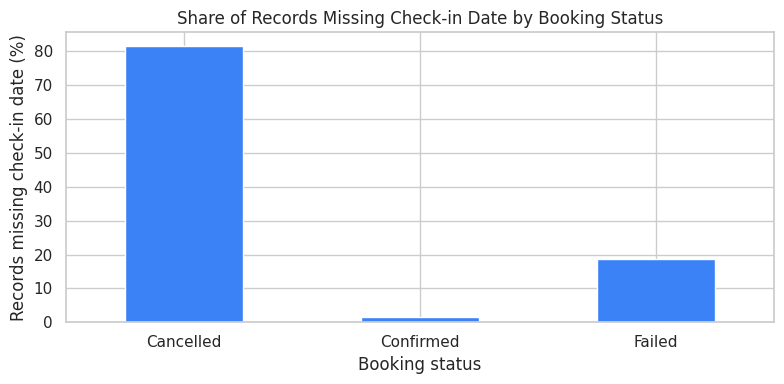

In [7]:
missing_plot = (df.assign(checkin_missing=df["check_in_date"].isna())
                 .groupby("booking_status")["checkin_missing"].mean() * 100)
ax = missing_plot.plot(kind="bar", figsize=(8, 4), color="#3B82F6")
ax.set_title("Share of Records Missing Check-in Date by Booking Status")
ax.set_ylabel("Records missing check-in date (%)")
ax.set_xlabel("Booking status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Date and numeric consistency checks
`length_of_stay` is compared with the difference between check-out and check-in dates where both dates exist. Financial columns are checked for arithmetic consistency; the checks do not automatically prove that a column represents recognized revenue or profit.

In [8]:
valid_stay_dates = df["check_in_date"].notna() & df["check_out_date"].notna()
date_based_stay = (df.loc[valid_stay_dates, "check_out_date"] -
                   df.loc[valid_stay_dates, "check_in_date"]).dt.days
stay_comparison = pd.DataFrame({
    "stored_length_of_stay": df.loc[valid_stay_dates, "length_of_stay"].values,
    "date_calculated_length_of_stay": date_based_stay.values
})
print("Valid records with both stay dates:", len(stay_comparison))
print("Stored vs date-derived stay exact match:",
      np.isclose(stay_comparison["stored_length_of_stay"],
                 stay_comparison["date_calculated_length_of_stay"]).mean())
print("Max absolute error in selling_price = costprice + markup:",
      (df["selling_price"] - df["costprice"] - df["markup"]).abs().max())

Valid records with both stay dates: 24532
Stored vs date-derived stay exact match: 1.0
Max absolute error in selling_price = costprice + markup: 3.637978807091713e-12


## 5. Cleaning decisions
- Preserve all records and all three booking statuses for descriptive analysis.
- Do not fill missing check-in/check-out dates or `length_of_stay` with a median.
- Parse date columns using `errors="coerce"` so invalid dates become missing and can be audited.
- Standardize text labels and the coupon-used field.
- Keep potential outliers for investigation; do not remove them without a business rule.
- For the binary cancellation model, use only `Cancelled` and `Confirmed` records. `Failed` records are excluded because failure is a different outcome from cancellation.

These choices avoid manufacturing dates or silently changing the population.

In [9]:
# Create derived fields only when source values support them.
df["booking_month"] = df["booking_date"].dt.month
df["booking_day_of_week"] = df["booking_date"].dt.day_name()
df["date_based_lead_time_days"] = (
    df["check_in_date"] - df["booking_date"]
).dt.days
df["date_based_length_of_stay"] = (
    df["check_out_date"] - df["check_in_date"]
).dt.days

# Save the cleaned analysis-ready table.
OUTPUT_PATH = Path("../data/hotel_bookings_cleaned.csv")
df.to_csv(OUTPUT_PATH, index=False)
print("Saved:", OUTPUT_PATH)
print("Final rows and columns:", df.shape)

Saved: ../data/hotel_bookings_cleaned.csv
Final rows and columns: (30000, 30)


## 6. Data quality summary
The original data contains 30,000 booking records and 26 columns. The missing check-in dates are not random across booking statuses, so analyses requiring check-in dates must use a clearly stated subset. The next notebook uses the full dataset for status/channel/city analysis and valid subsets for stay-date analysis.